# 04 — Detecção de ruídos e outliers

## 1. Leitura da base limpa

In [1]:
from importlib.util import find_spec
from pathlib import Path

import pandas as pd

if find_spec("google") is not None and find_spec("google.colab") is not None:
    pasta_dados = Path("/content/PROJETO-COLETA-E-RASPAGEM-DE-DADOS/dados")
    if not pasta_dados.exists():
        from google.colab import drive

        drive.mount("/content/drive")
        pasta_dados = Path("/content/drive/MyDrive/PROJETO-COLETA-E-RASPAGEM-DE-DADOS/dados")
else:
    pasta_dados = Path("../dados")

df = pd.read_parquet(pasta_dados / "queimadas_limpo.parquet")

## 2. Boxplots de `FRP` e `DiaSemChuva`

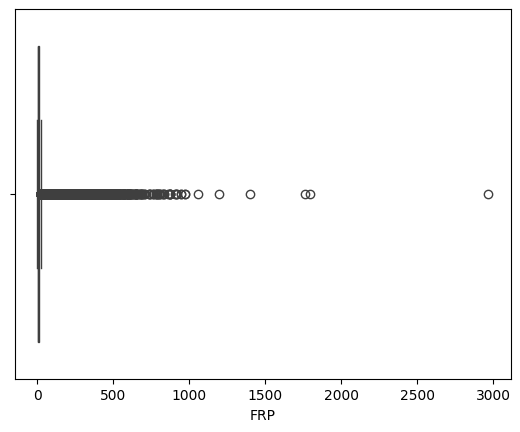

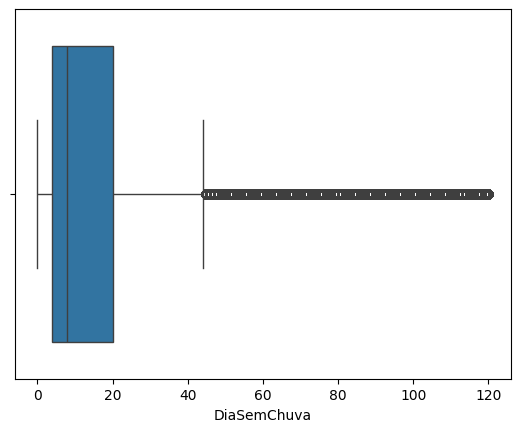

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.boxplot(x=df["FRP"])
plt.show()

plt.figure()
sns.boxplot(x=df["DiaSemChuva"])
plt.show()

## 3. Limites e contagem de outliers pelo método IQR

In [3]:
variaveis = df[["FRP", "DiaSemChuva"]]
q1 = variaveis.quantile(0.25)
q3 = variaveis.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers = (variaveis < limite_inferior) | (variaveis > limite_superior)

display(pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "limite_inferior": limite_inferior,
    "limite_superior": limite_superior,
    "quantidade_outliers": outliers.sum(),
}))

,Q1,Q3,IQR,limite_inferior,limite_superior,quantidade_outliers
FRP,2.7,10.9,8.2,-9.6,23.2,155080
DiaSemChuva,4.0,20.0,16.0,-20.0,44.0,186327


## 4. Marcação de outliers de `FRP`

Eu mantenho esses registros porque valores altos de FRP podem representar grandes incêndios reais.

In [4]:
df["outlier_frp"] = df["FRP"] > limite_superior["FRP"]